# 01. Khảo sát dữ liệu Georgia Tech Face Database

**Mục tiêu:** kiểm tra cấu trúc và quy mô dữ liệu, trực quan hóa ảnh và xác minh file cặp ảnh dùng cho notebook 02. Dữ liệu gốc lưu cục bộ trong `data/gt_db/`.

**Lưu ý:** notebook này chỉ *đọc và kiểm tra* `pairs.csv` nếu đã có; không tạo lại cặp ảnh, tránh làm thay đổi tập đánh giá và khiến kết quả notebook 02 không còn tương ứng.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import cv2

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "gt_db").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy data/gt_db trong các thư mục cha")
    ROOT = ROOT.parent

DATASET_DIR = ROOT / "data" / "gt_db"

assert DATASET_DIR.is_dir(), f"Không tìm thấy: {DATASET_DIR}"

print("Project root:", ROOT)
print("Dataset:", DATASET_DIR)

Project root: C:\Users\NAO\Downloads\lab5_face_ID
Dataset: C:\Users\NAO\Downloads\lab5_face_ID\data\gt_db


In [2]:
# thống kê số lượng ảnh trong dataset
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for person_dir in sorted(DATASET_DIR.iterdir()):
    if not person_dir.is_dir():
        continue

    image_paths = [
        p for p in person_dir.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    ]

    records.append({
        "person_id": person_dir.name,
        "image_count": len(image_paths)
    })

df = pd.DataFrame(records)

display(df)

print("Total persons:", len(df))
print("Total images:", df["image_count"].sum())
print("Min images/person:", df["image_count"].min())
print("Max images/person:", df["image_count"].max())

,person_id,image_count
0,s01,15
1,s02,15
2,s03,15
3,s04,15
4,s05,15
5,s06,15
6,s07,15
7,s08,15
8,s09,15
9,s10,15


Total persons: 50
Total images: 750
Min images/person: 15
Max images/person: 15


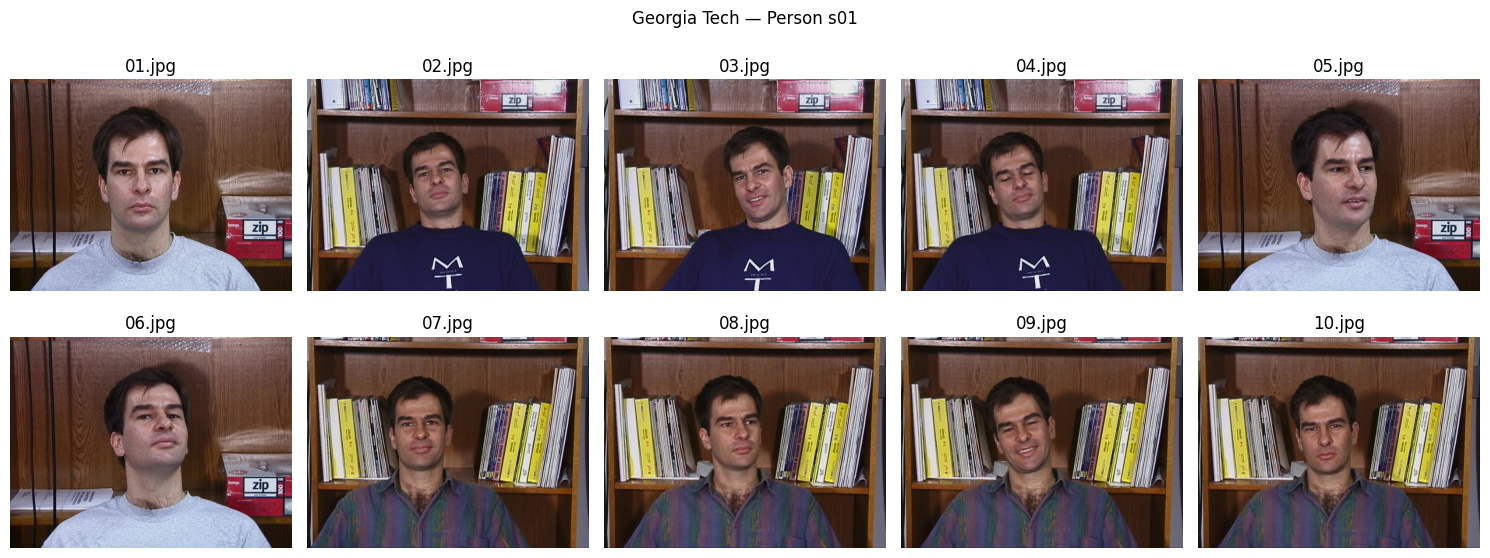

In [3]:
# Hiển thị ảnh 1 người
person_dir = DATASET_DIR / "s01"

image_paths = sorted(
    p for p in person_dir.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)[:10]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, path in zip(axes.flat, image_paths):
    image = cv2.imread(str(path))

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image)

    ax.set_title(path.name)
    ax.axis("off")

for ax in axes.flat[len(image_paths):]:
    ax.axis("off")

plt.suptitle("Georgia Tech — Person s01")
plt.tight_layout()
plt.show()

## Kiểm tra tập cặp ảnh dùng cho notebook 02

File `data/pair_evaluation/pairs.csv` gồm `image1`, `image2`, `label` (`1 = Same`, `0 = Different`). Kiểm tra số lượng cặp, nhãn, đường dẫn và số ảnh duy nhất mà **không sửa file**. Trong lần đánh giá đã lưu: 100 cặp, 50 Same và 50 Different, 91 ảnh duy nhất. Các ảnh có thể xuất hiện ở nhiều cặp.

In [4]:
PAIRS_CSV = ROOT / "data" / "pair_evaluation" / "pairs.csv"
if PAIRS_CSV.exists():
    pairs_df = pd.read_csv(PAIRS_CSV)
    required = {"image1", "image2", "label"}
    assert required.issubset(pairs_df.columns), f"Thiếu cột: {required - set(pairs_df.columns)}"
    assert set(pairs_df["label"].dropna().unique()).issubset({0, 1})
    paths = set(pairs_df["image1"]) | set(pairs_df["image2"])
    missing = [p for p in paths if not (ROOT / str(p).replace("\\", "/")).is_file()]
    print("Số cặp:", len(pairs_df))
    print("Same:", int((pairs_df["label"] == 1).sum()))
    print("Different:", int((pairs_df["label"] == 0).sum()))
    print("Ảnh duy nhất:", len(paths))
    print("Đường dẫn thiếu:", len(missing))
    display(pairs_df.head())
else:
    print("Chưa có pairs.csv. Notebook 02 cần file này để chạy phần đánh giá theo cặp.")

Số cặp: 100
Same: 50
Different: 50
Ảnh duy nhất: 91
Đường dẫn thiếu: 0


,image1,image2,label
0,data\gt_db\s18\01.jpg,data\gt_db\s18\10.jpg,1
1,data\gt_db\s15\01.jpg,data\gt_db\s15\13.jpg,1
2,data\gt_db\s02\14.jpg,data\gt_db\s09\15.jpg,0
3,data\gt_db\s18\04.jpg,data\gt_db\s41\01.jpg,0
4,data\gt_db\s02\15.jpg,data\gt_db\s02\05.jpg,1
